# Tổng hợp kết quả dự báo giá gạo xuất khẩu Việt Nam 5% tấm (2023-2025)

Notebook tổng hợp kết quả chạy 4 mô hình dự báo trước 1 tháng ($h = 1$) từ dữ liệu giá tầng Gold của hệ thống Lakehouse.

| Hạng mục | Thiết lập |
|---|---|
| **Chuỗi mục tiêu ($y_t$)** | `rice_viet_namese_5` (World Bank Pink Sheet, giá FOB bình quân tháng, USD/tấn) |
| **Phạm vi dữ liệu** | 01/2010 đến 12/2025 (192 tháng, không khuyết giá trị mục tiêu; năm 2009 dùng để tạo biến trễ) |
| **Chia tập train/test** | Train 2010-2022 (156 tháng), Test 2023-2025 (36 tháng) |
| **4 mô hình so sánh** | `naive` (baseline), `sarima` (`SARIMA(2,1,1)(0,0,0)[12]` trên log giá), `xgb_base` (14 đặc trưng nội sinh và chi phí đầu vào), `xgb_competitor` (20 đặc trưng, thêm 6 đặc trưng giá gạo đối thủ) |
| **Một số thiết lập chính** | XGBoost dự báo mức thay đổi giá $\Delta y_{t+1} = y_{t+1} - y_t$ rồi cộng lại vào $y_t$; giữ nguyên `NaN` ở biến giá đối thủ để XGBoost tự xử lý; tất cả đặc trưng chỉ lấy từ tháng $t$ trở về trước để tránh rò rỉ dữ liệu |

## 1. Đọc dữ liệu và kiểm tra kết quả dự báo

Đọc các file kết quả trong `exports/forecast/` và kiểm tra đủ 36 tháng test (202301-202512) cho 4 mô hình (144 dòng).

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "jobs").is_dir():
    ROOT = ROOT.parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from jobs.forecasting.metrics import evaluate_predictions
from jobs.forecasting.summarize_forecasts import (
    FI_CSV,
    GOLD_CSV,
    MART_CSV,
    MODELS_DIR,
    load_and_merge_predictions,
    plot_actual_vs_predicted,
    plot_actual_vs_predicted_by_period,
    plot_metrics_and_importance,
    plot_wb_vs_usda_zoom,
)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
gold_df = pd.read_csv(GOLD_CSV)
mart_df = pd.read_csv(MART_CSV)
fi_df = pd.read_csv(FI_CSV)
pred_df = load_and_merge_predictions(mart_df, models_dir=MODELS_DIR, require_all=True)
metrics_df = evaluate_predictions(pred_df)
pred_df["model_name"].value_counts()

model_name
naive             36
sarima            36
xgb_base          36
xgb_competitor    36
Name: count, dtype: int64

## 2. Đối chiếu nguồn giá World Bank và USDA

Trước khi đánh giá mô hình, so sánh chuỗi mục tiêu World Bank (`rice_viet_namese_5`) với nguồn độc lập USDA Rice Yearbook (đã quy đổi niên vụ tháng 8-7 về lịch dương) để kiểm tra mức độ thống nhất của dữ liệu giá.

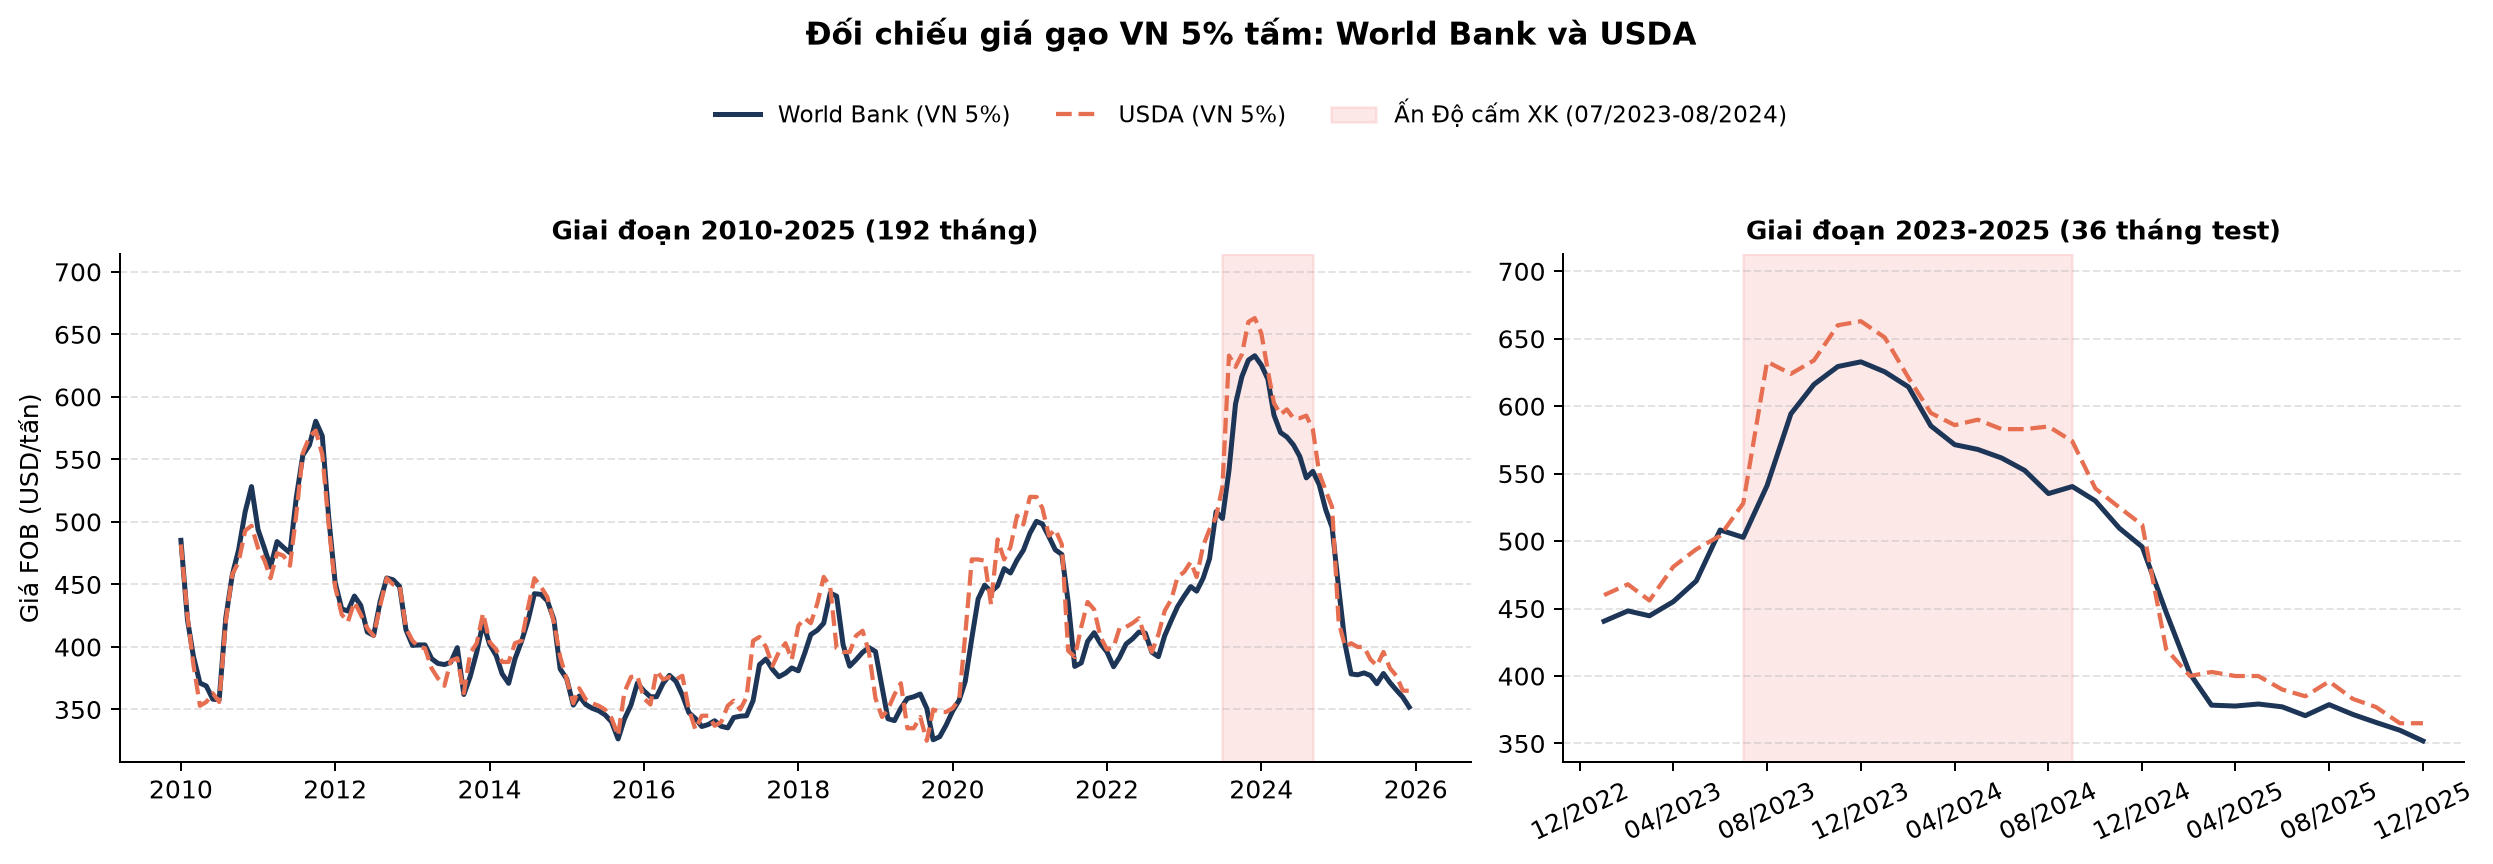

In [2]:
fig = plot_wb_vs_usda_zoom(gold_df)
plt.show()

In [3]:
rows = []
for label, start_mk, end_mk in [("2010-2025", 201001, 202512), ("2023-2025", 202301, 202512)]:
    sub = gold_df[gold_df["month_key"].between(start_mk, end_mk)].copy()
    diff = sub["wb_vn5_usd_t"] - sub["usda_vn5_usd_t"]
    max_idx = diff.abs().idxmax()
    rows.append({
        "Giai đoạn": label,
        "Số tháng": len(sub),
        "Tương quan (r)": round(sub["wb_vn5_usd_t"].corr(sub["usda_vn5_usd_t"]), 4),
        "Lệch TB (WB - USDA)": round(diff.mean(), 2),
        "Lệch tuyệt đối TB (USD/tấn)": round(diff.abs().mean(), 2),
        "Lệch lớn nhất (USD/tấn)": round(diff.loc[max_idx], 2),
        "Tháng lệch nhất": int(sub.loc[max_idx, "month_key"]),
    })

display(pd.DataFrame(rows))
gold_df.loc[gold_df["month_key"].isin([202308, 202312]), ["month_key", "wb_vn5_usd_t", "usda_vn5_usd_t"]].round(2)

,Giai đoạn,Số tháng,Tương quan (r),Lệch TB (WB - USDA),Lệch tuyệt đối TB (USD/tấn),Lệch lớn nhất (USD/tấn),Tháng lệch nhất
0,2010-2025,192,0.9731,-7.79,14.13,-91.85,202308
1,2023-2025,36,0.9852,-19.43,21.27,-91.85,202308


,month_key,wb_vn5_usd_t,usda_vn5_usd_t
175,202308,541.15,633.0
179,202312,632.90,663.0


### Nhận xét
- Trong cả giai đoạn 2010-2025 (192 tháng), hai nguồn World Bank và USDA bám khá sát nhau về xu hướng (tương quan r = 0.9731, chênh lệch tuyệt đối trung bình 14.13 USD/tấn, giá World Bank trung bình thấp hơn USDA 7.79 USD/tấn).
- Riêng giai đoạn test 2023-2025, hệ số tương quan vẫn rất cao (0.9852) nhưng mức chênh lệch tuyệt đối trung bình tăng lên 21.27 USD/tấn. Tháng lệch mạnh nhất là 08/2023 (-91.85 USD/tấn, WB 541.15 so với USDA 633.00 USD/tấn) ngay sau lệnh cấm xuất khẩu gạo trắng của Ấn Độ (07/2023), do hai nguồn cập nhật biến động giá hơi lệch nhịp.
- Tuy vậy, cả hai nguồn đều phản ánh chung nhịp tăng mạnh cuối năm 2023 (đỉnh tháng 12/2023: WB 632.90, USDA 663.00 USD/tấn) và xu hướng giảm kéo dài trong 2024-2025, cho thấy dữ liệu đầu vào đủ tin cậy.

## 3. Bảng tổng hợp sai số dự báo theo 3 giai đoạn

Đánh giá 4 mô hình trên 3 lát cắt thời gian: toàn kỳ 2023-2025 (36 tháng), giai đoạn tăng sốc 2023 (12 tháng) và giai đoạn giảm 2024-2025 (24 tháng).

In [4]:
table = metrics_df.pivot(index="model_name", columns="eval_period", values=["mae", "rmse", "mape"])
table.reindex(index=["naive", "sarima", "xgb_base", "xgb_competitor"]).reindex(
    columns=["2023-2025", "2023", "2024-2025"], level=1
).round(2)

mae                   ...      mape                
eval_period    2023-2025   2023 2024-2025  ... 2023-2025  2023 2024-2025
model_name                                 ...                          
naive              14.71  18.23     12.95  ...      3.01  3.39      2.81
sarima             14.29  19.58     11.64  ...      2.98  3.64      2.64
xgb_base           15.66  27.21      9.88  ...      3.15  5.06      2.20
xgb_competitor     12.50  20.67      8.41  ...      2.51  3.77      1.88

[4 rows x 9 columns]

### Nhận xét
- Xét toàn kỳ 2023-2025, `xgb_competitor` có sai số thấp nhất ở cả 3 chỉ số (MAE = 12.50 USD/tấn, RMSE = 18.18 USD/tấn, MAPE = 2.51%), giảm 15.0% MAE so với `naive` (14.71) và 20.2% so với `xgb_base` (15.66). `sarima` xếp thứ hai (MAE = 14.29), còn `xgb_base` cao hơn cả `naive`.
- Riêng năm 2023, `naive` lại cho sai số thấp nhất (MAE = 18.23 USD/tấn, MAPE = 3.39%), vượt qua `sarima` (19.58), `xgb_competitor` (20.67) và `xgb_base` (27.21).
- Sang giai đoạn 2024-2025, cả 3 mô hình đều tốt hơn `naive` (MAE = 12.95), trong đó `xgb_competitor` dẫn đầu với MAE = 8.41 USD/tấn (MAPE = 1.88%, thấp hơn `naive` 35.1%).

## 4. So sánh đường giá thực tế và dự báo (2023-2025)

Đối chiếu đường giá thực tế với dự báo 1 bước của 4 mô hình. Vùng tô đỏ là thời gian Ấn Độ cấm xuất khẩu gạo trắng (07/2023-08/2024), vạch chấm dọc ngăn cách năm 2023 với giai đoạn 2024-2025.

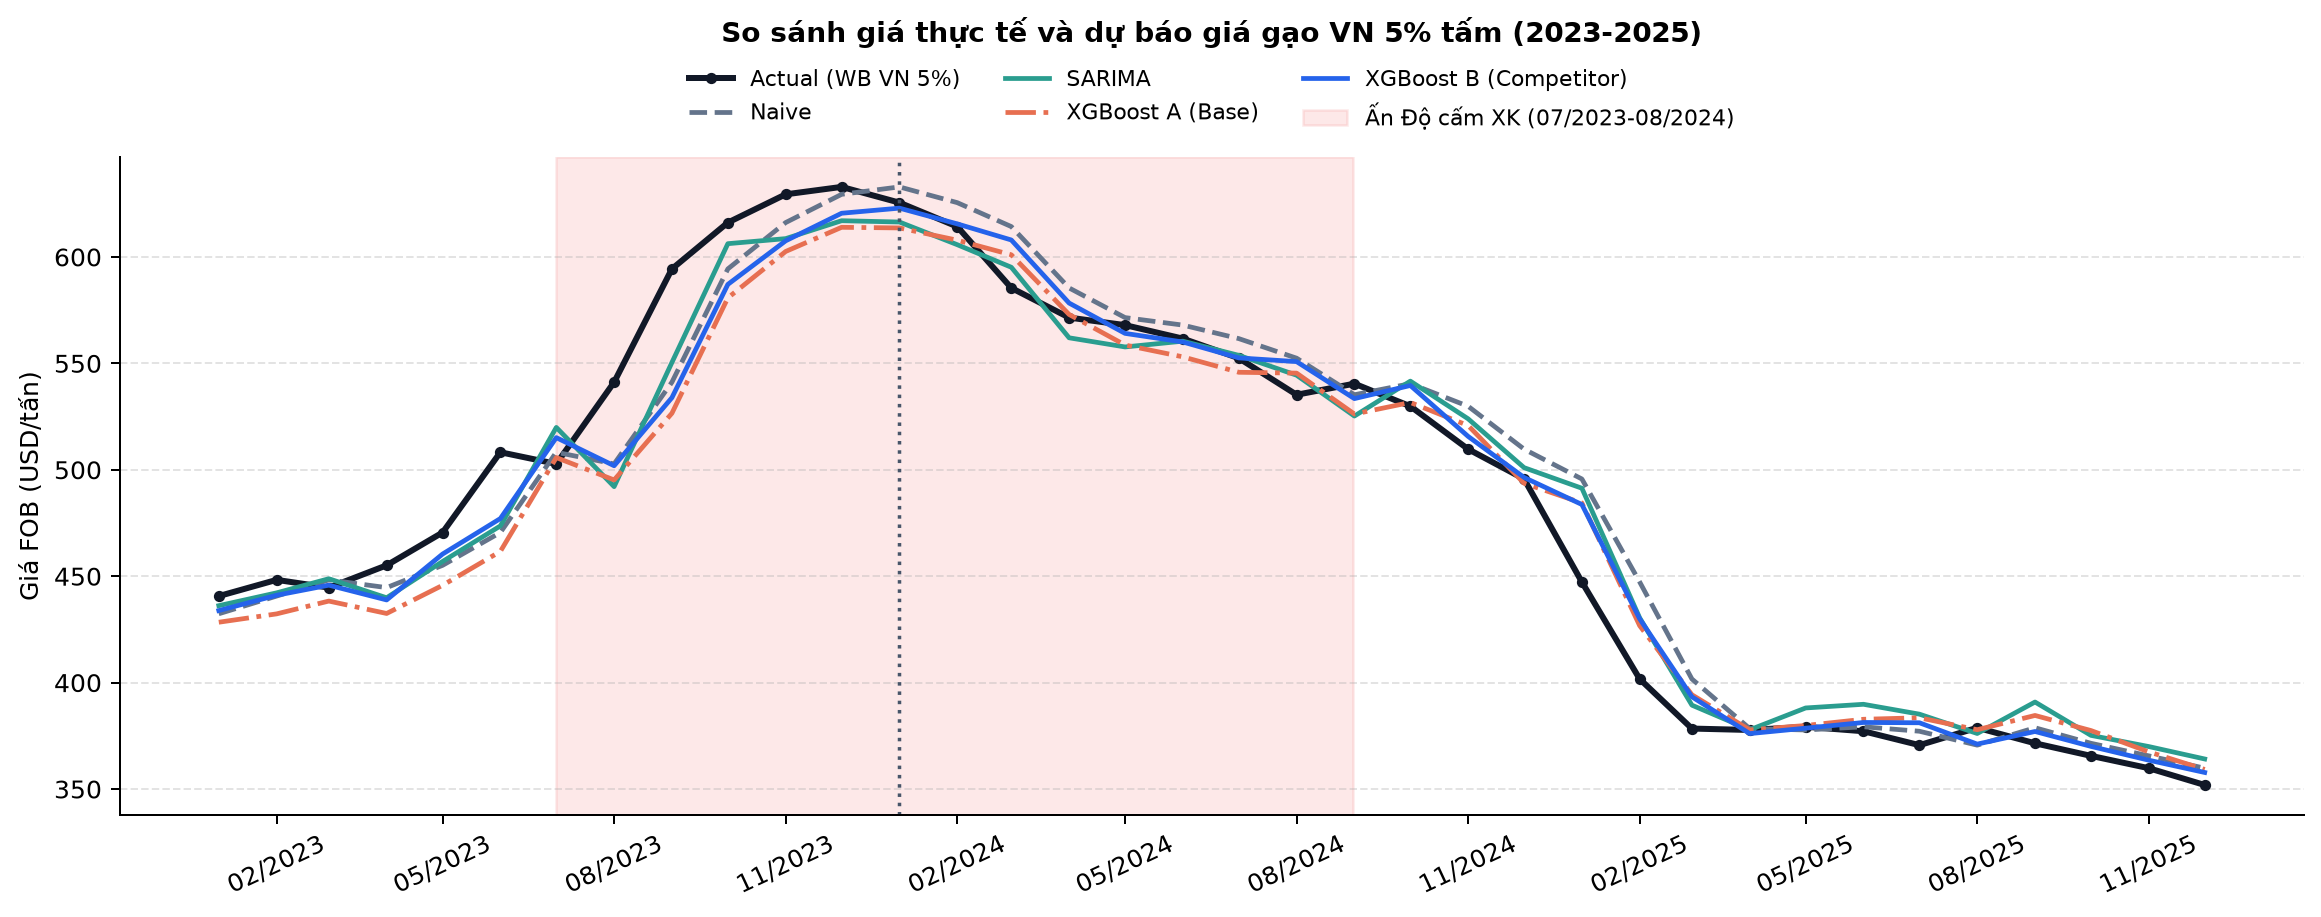

In [5]:
fig = plot_actual_vs_predicted(pred_df)
plt.show()

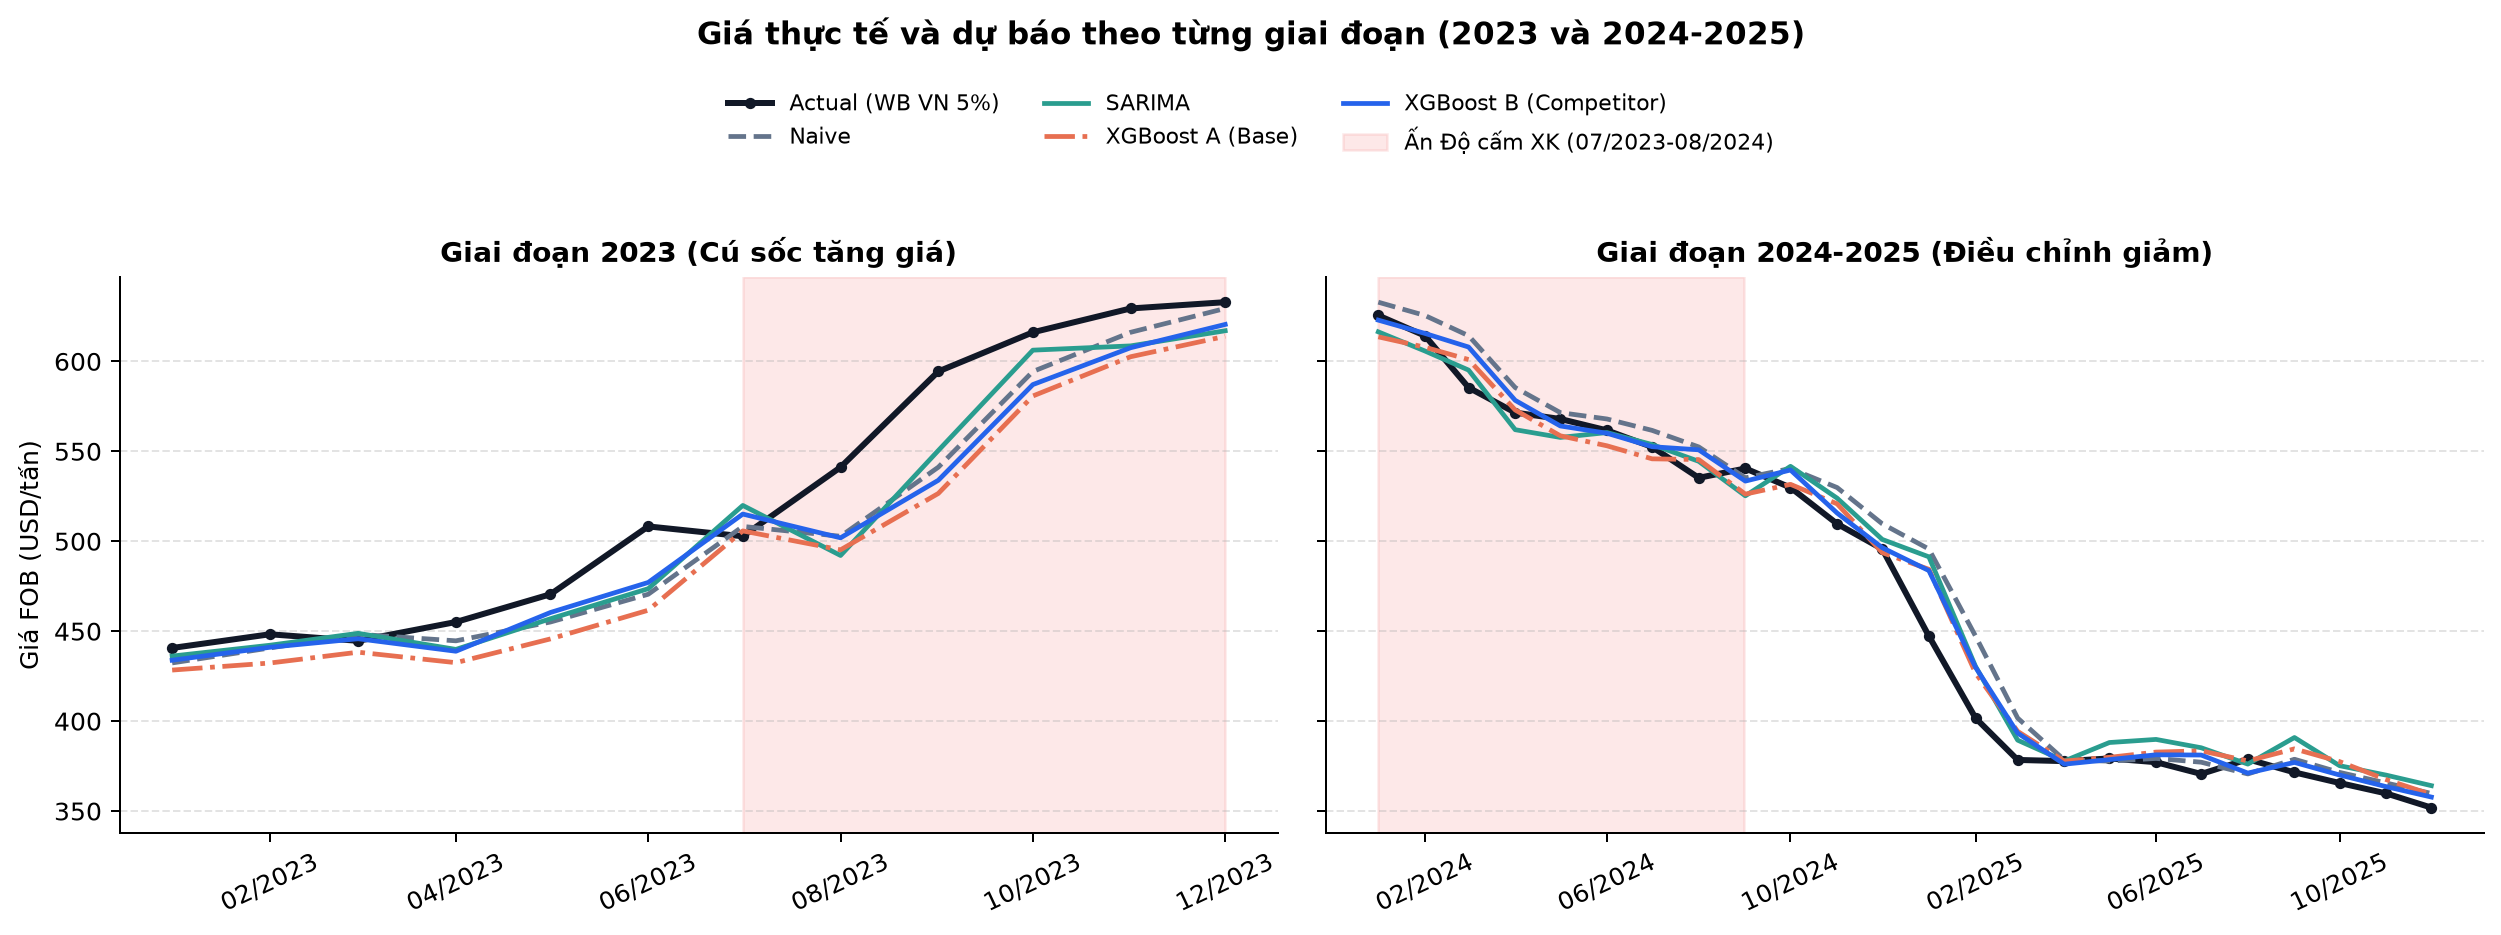

In [6]:
fig = plot_actual_vs_predicted_by_period(pred_df)
plt.show()

In [7]:
train_max = mart_df.loc[mart_df["split"] == "train", "y"].max()
test_y = mart_df[mart_df["split"] == "test"]
over_peak = test_y[test_y["y"] > train_max]
print(f"Đỉnh tập train (2010-2022): {train_max:.2f} USD/tấn")
print(
    f"Số tháng test vượt đỉnh train: {len(over_peak)} tháng "
    f"({int(over_peak['month_key'].min())}-{int(over_peak['month_key'].max())}, "
    f"đỉnh {over_peak['y'].max():.2f} USD/tấn)"
)

p24 = pred_df[pred_df["month_key"].between(202401, 202512)].assign(abs_err=lambda d: d["error_usd_t"].abs())
best_counts = p24.loc[p24.groupby("month_key")["abs_err"].idxmin(), "model_name"].value_counts()

summary_behavior = pd.DataFrame({
    "Dự báo cao nhất 2023-2025 (USD/tấn)": pred_df.groupby("model_name")["predicted_usd_t"].max().round(2),
    "Số tháng lỗi nhỏ nhất (2024-2025)": best_counts,
}).reindex(["naive", "sarima", "xgb_base", "xgb_competitor"])
summary_behavior

Đỉnh tập train (2010-2022): 580.54 USD/tấn
Số tháng test vượt đỉnh train: 7 tháng (202309-202403, đỉnh 632.90 USD/tấn)


,Dự báo cao nhất 2023-2025 (USD/tấn),Số tháng lỗi nhỏ nhất (2024-2025)
model_name,,
naive,632.90,4
sarima,617.02,4
xgb_base,613.92,6
xgb_competitor,622.93,10


### Nhận xét
- Nhờ cho XGBoost học sai phân $\Delta y$ rồi cộng lại vào $y_t$, cả `xgb_base` (đạt đỉnh dự báo 613.92 USD/tấn) và `xgb_competitor` (622.93 USD/tấn) đều vượt được mức đỉnh lịch sử của tập train (580.54 USD/tấn) trong 7 tháng giá tăng cao liên tiếp (09/2023-03/2024), không bị kẹt trần như cây quyết định dự báo trực tiếp mức giá.
- Trong năm 2023, đường `xgb_base` nằm thấp hơn hẳn giá thực từ tháng 04 đến tháng 12 do chỉ dựa vào lịch sử giá Việt Nam nên có xu hướng kéo dự báo về mặt bằng cũ. Khi thêm giá gạo đối thủ, `xgb_competitor` bám sát thực tế hơn rõ rệt.
- Trong giai đoạn hạ nhiệt 2024-2025, đường `naive` liên tục nằm cao hơn giá thực (rõ nhất ở đợt giảm đầu năm 2025) vì bị trễ 1 tháng. `xgb_competitor` bám sát đường thực tế nhất và đạt sai số nhỏ nhất ở 10/24 tháng.

## 5. So sánh sai số đa giai đoạn và mức độ quan trọng đặc trưng

Phần trên so sánh MAE, RMSE, MAPE của 4 mô hình; phần dưới xem các đặc trưng đóng góp nhiều nhất trong `xgb_competitor` theo Gain Share trên tập train và Permutation Importance ($\Delta\text{RMSE}$) trên tập test.

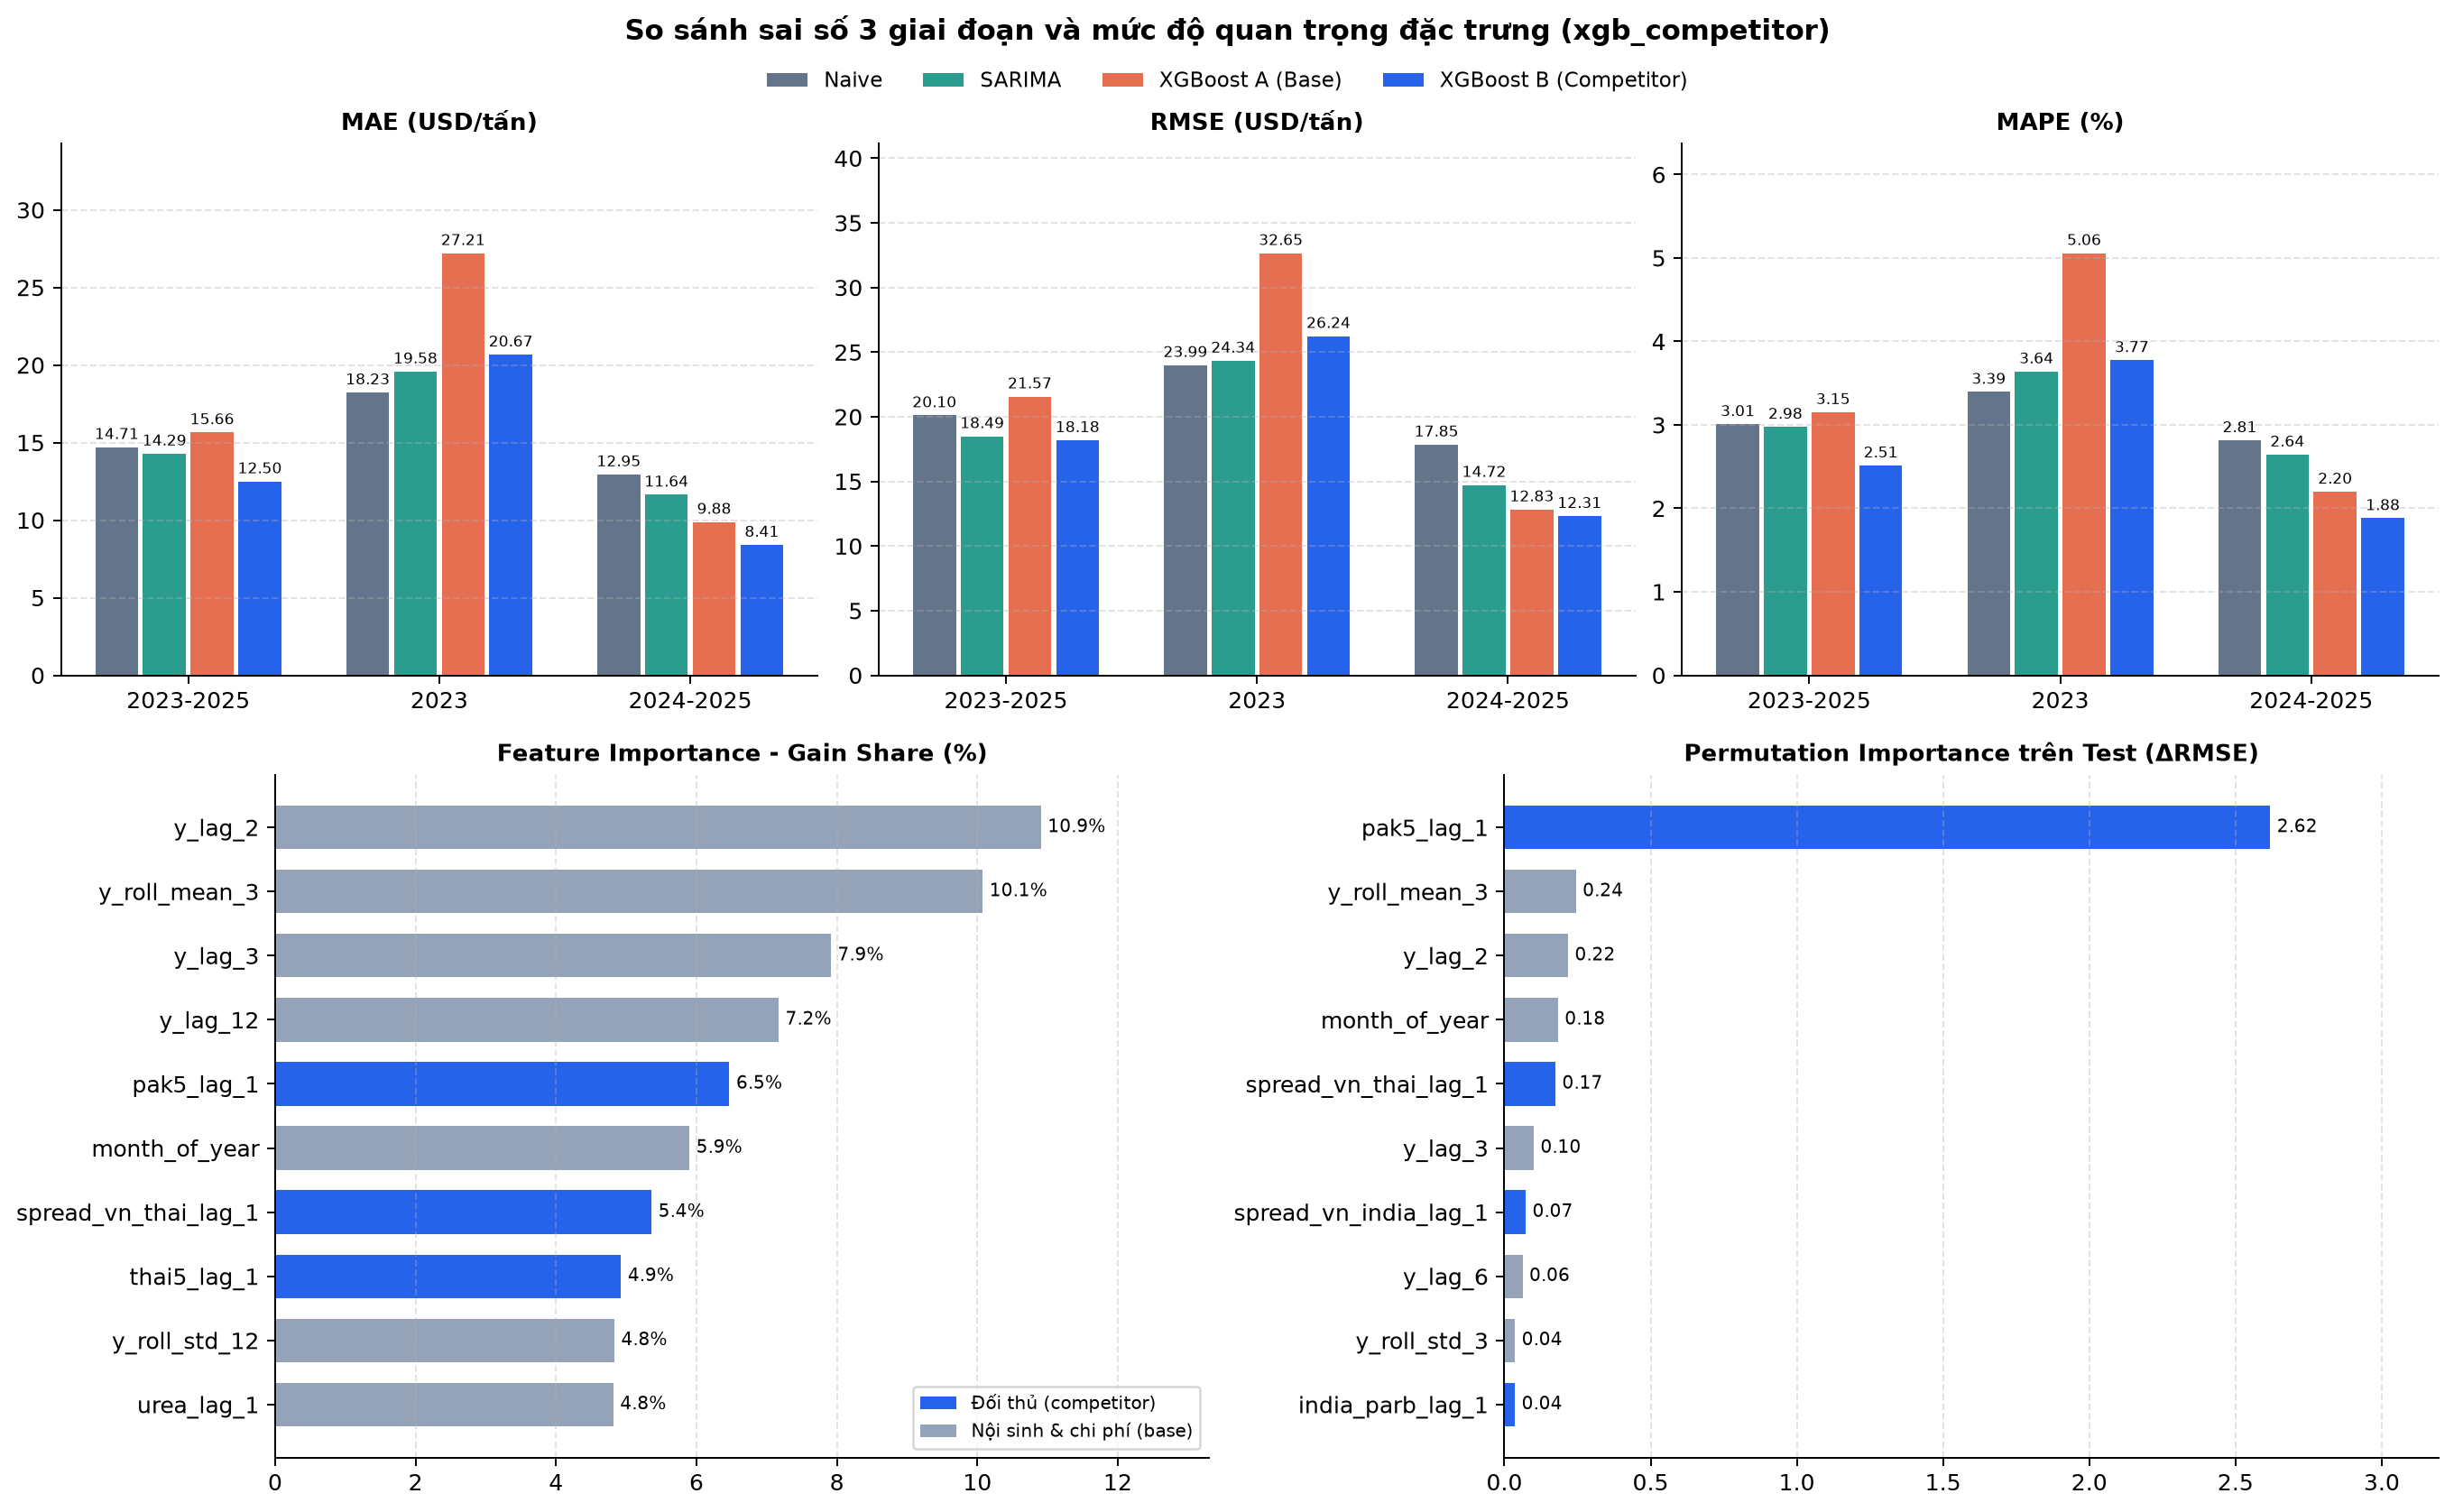

In [8]:
fig = plot_metrics_and_importance(metrics_df, fi_df, top_n=10)
plt.show()

In [9]:
fi_comp = fi_df[fi_df["model_name"] == "xgb_competitor"].copy()
display(fi_comp.groupby("feature_group")[["gain_share_pct"]].sum().round(2))
fi_comp[fi_comp["feature_group"] == "competitor"][
    ["feature", "feature_group", "gain_share_pct", "perm_test_rmse_mean"]
].round(2)

,gain_share_pct
feature_group,
base,75.48
competitor,24.52


,feature,feature_group,gain_share_pct,perm_test_rmse_mean
18,pak5_lag_1,competitor,6.47,2.62
20,spread_vn_thai_lag_1,competitor,5.36,0.17
21,thai5_lag_1,competitor,4.93,-0.00
26,spread_vn_india_lag_1,competitor,4.12,0.07
27,india_parb_lag_1,competitor,3.64,0.04
33,india_white_quote_missing_lag_1,competitor,0.00,0.00


### Nhận xét
- `xgb_competitor` cải thiện sai số so với `xgb_base` ở cả 3 giai đoạn và trên cả 3 chỉ số (MAE giảm 24.0% năm 2023, 20.2% toàn kỳ và 14.9% giai đoạn 2024-2025).
- Tổng 6 biến giá đối thủ chiếm 24.52% tổng Gain của `xgb_competitor`. Đáng chú ý nhất là `pak5_lag_1` (giá gạo Pakistan 5% tấm): dù chỉ đứng thứ 5 về Gain (6.47%), nhưng lại có Permutation Importance trên tập test cao nhất mô hình (+2.62 USD/tấn RMSE), vượt xa đặc trưng đứng thứ hai là `y_roll_mean_3` (+0.24). Các biến chênh lệch giá khu vực như `spread_vn_thai_lag_1` (Gain 5.36%, perm +0.17), `spread_vn_india_lag_1` (Gain 4.12%, perm +0.07) và `india_parb_lag_1` (Gain 3.64%, perm +0.04) cũng đóng góp dương.
- Riêng cờ báo khuyết báo giá gạo trắng Ấn Độ (`india_white_quote_missing_lag_1`) có Gain bằng 0% vì trong tập train biến này ít xuất hiện và bối cảnh khác đợt cấm xuất khẩu 2023-2024, nên cây quyết định không chọn chia nhánh theo biến này. Tác động từ thị trường Ấn Độ đi vào mô hình chủ yếu qua giá của Pakistan, Thái Lan và gạo Ấn Độ Parboiled.

## 6. Top 10 tháng có sai số lớn nhất

Lọc 10 dòng có $|y_{t+1} - \hat{y}_{t+1}|$ lớn nhất trên toàn bộ 144 dự báo test để xem các mô hình thường sai mạnh ở giai đoạn nào.

In [10]:
pred_df.assign(abs_err=pred_df["error_usd_t"].abs()).sort_values(
    "abs_err", ascending=False
).head(10)[
    ["month_key", "model_name", "actual_usd_t", "predicted_usd_t", "error_usd_t", "abs_pct_error"]
].round(2)

,month_key,model_name,actual_usd_t,predicted_usd_t,error_usd_t,abs_pct_error
80,202309,xgb_base,594.37,526.56,67.81,11.41
116,202309,xgb_competitor,594.37,533.88,60.49,10.18
8,202309,naive,594.37,541.15,53.22,8.95
43,202308,sarima,541.15,492.08,49.07,9.07
24,202501,naive,447.27,495.67,-48.40,10.82
77,202306,xgb_base,508.24,461.65,46.59,9.17
79,202308,xgb_base,541.15,495.22,45.93,8.49
25,202502,naive,401.70,447.27,-45.57,11.34
60,202501,sarima,447.27,491.33,-44.06,9.85
44,202309,sarima,594.37,550.42,43.95,7.39


### Nhận xét
- Phần lớn lỗi lớn rơi vào hai thời điểm thị trường biến động đột ngột: 7/10 dòng nằm ở đợt tăng mạnh năm 2023 (tháng 06, 08, 09/2023) và 3/10 dòng nằm ở đợt giảm sâu đầu năm 2025 (01-02/2025, sau khi Ấn Độ dỡ lệnh cấm xuất khẩu).
- Tháng 09/2023 là tháng khó dự báo nhất khi cả 4 mô hình đều lọt Top 10 lỗi do giá tăng vọt 53.22 USD/tấn chỉ trong một tháng (từ 541.15 lên 594.37 USD/tấn), trong đó `xgb_base` sai cao nhất (67.81 USD/tấn, tương đương 11.41%).
- Trong 10 dòng sai số lớn nhất, `xgb_base`, `naive` và `sarima` đều xuất hiện 3 lần, còn `xgb_competitor` chỉ xuất hiện 1 lần (tháng 09/2023: 60.49 USD/tấn) và không lọt nhóm sai số cao nhất ở đợt giảm đầu 2025.

## 7. Giải thích hành vi mô hình và tổng kết

Kiểm tra tự tương quan bậc 1 của chuỗi giá và mức thay đổi giá trung bình theo từng giai đoạn để lý giải vì sao `naive` thắng năm 2023 còn `xgb_competitor` thắng 2024-2025.

In [11]:
m_tr = mart_df[mart_df["split"] == "train"].sort_values("month_key")
m_te = mart_df[mart_df["split"] == "test"].sort_values("month_key")
dy_te = m_te["y"] - m_te["y_lag_1"]

series_stats = pd.DataFrame([
    {"Chỉ tiêu": "Tự tương quan bậc 1 của y (train 2010-2022)", "Giá trị": round(m_tr["y"].autocorr(1), 4)},
    {"Chỉ tiêu": "Tự tương quan bậc 1 của y (test 2023-2025)", "Giá trị": round(m_te["y"].autocorr(1), 4)},
    {"Chỉ tiêu": "Tự tương quan bậc 1 của Δy (test 2023-2025)", "Giá trị": round(dy_te.autocorr(1), 4)},
    {"Chỉ tiêu": "Biến động giá thực TB/tháng năm 2023 (USD/tấn)", "Giá trị": round(dy_te[m_te["month_key"] <= 202312].mean(), 2)},
    {"Chỉ tiêu": "Biến động giá thực TB/tháng 2024-2025 (USD/tấn)", "Giá trị": round(dy_te[m_te["month_key"] >= 202401].mean(), 2)},
])
display(series_stats)

p23 = pred_df[pred_df["month_key"].between(202301, 202312)].merge(
    m_te[["month_key", "y_lag_1"]], on="month_key"
)
p23["pred_delta"] = p23["predicted_usd_t"] - p23["y_lag_1"]
p23.groupby("model_name")[["pred_delta"]].mean().reindex(
    ["naive", "sarima", "xgb_base", "xgb_competitor"]
).rename(columns={"pred_delta": "Dự báo Δy TB năm 2023 (USD/tấn)"}).round(2)

,Chỉ tiêu,Giá trị
0,Tự tương quan bậc 1 của y (train 2010-2022),0.9389
1,Tự tương quan bậc 1 của y (test 2023-2025),0.9758
2,Tự tương quan bậc 1 của Δy (test 2023-2025),0.6351
3,Biến động giá thực TB/tháng năm 2023 (USD/tấn),16.7100
4,Biến động giá thực TB/tháng 2024-2025 (USD/tấn),-11.7100


,Dự báo Δy TB năm 2023 (USD/tấn)
model_name,
naive,0.00
sarima,0.68
xgb_base,-10.00
xgb_competitor,-1.71


### Kết quả chính
- So với baseline `naive`: tính chung cả giai đoạn 2023-2025, `xgb_competitor` (MAE = 12.50, MAPE = 2.51%) và `sarima` (14.29, 2.98%) vượt `naive` (14.71, 3.01%), trong khi `xgb_base` (15.66, 3.15%) kém hơn. Tuy nhiên kết quả phụ thuộc vào diễn biến thị trường: năm 2023 `naive` thấp nhất (18.23), còn giai đoạn 2024-2025 cả 3 mô hình đều thắng `naive`, tốt nhất là `xgb_competitor` (8.41).
- Vai trò của giá đối thủ: thêm 6 đặc trưng giá đối thủ giúp `xgb_competitor` giảm MAE so với `xgb_base` ở mọi giai đoạn (-20.2% toàn kỳ, -24.0% năm 2023 và -14.9% giai đoạn 2024-2025).

### Vì sao hành vi mô hình khác nhau giữa 2023 và 2024-2025
- Chuỗi giá gạo theo tháng có tự tương quan bậc 1 rất cao (0.9389 trên train, 0.9758 trên test), nên với tầm dự báo 1 tháng, `naive` ($\hat{y}_{t+1} = y_t$) là mốc so sánh khá mạnh.
- Năm 2023 xảy ra cú sốc chính sách chưa có trong dữ liệu huấn luyện 2010-2022 (Ấn Độ cấm xuất khẩu), giá thực tăng bình quân +16.71 USD/tấn/tháng. Vì tham số mô hình được giữ cố định sau năm 2022, `xgb_base` có xu hướng kéo dự báo quay về vùng giá lịch sử (dự báo $\Delta y$ trung bình -10.00 USD/tấn/tháng), khiến sai số tăng cao. `naive` không kéo giá xuống nên ít bị lệch hơn trong năm này. Khi có thêm giá Pakistan, Thái Lan và Ấn Độ Parboiled, độ lệch âm của `xgb_competitor` giảm mạnh từ -10.00 còn -1.71 USD/tấn/tháng.
- Sang giai đoạn 2024-2025, giá giảm có quán tính rõ hơn (trung bình -11.71 USD/tấn/tháng, tự tương quan $\Delta y$ đạt 0.6351), giúp `sarima` và đặc biệt là `xgb_competitor` khai thác tốt xu hướng và vượt xa `naive`.

### Hạn chế và hướng mở rộng
- Giữ nguyên tham số mô hình suốt 3 năm test giúp đánh giá tách biệt nhưng làm mô hình thích nghi chậm khi có cú sốc mới; có thể cải thiện bằng cách huấn luyện lại định kỳ theo cửa sổ mở rộng (expanding-window refit).
- Hiện bài toán chỉ dự báo trước 1 tháng dựa trên dữ liệu giá lịch sử; hướng phát triển tiếp theo là thử nghiệm dự báo nhiều bước ($h = 3, 6$ tháng) và bổ sung thêm chỉ báo tồn kho/cung cầu toàn cầu (như USDA PSD).